# 07 — Statistical Validation
## Airtel Telecom Analytics | Recharge Behaviour & Customer Retention Analysis

**Analysis period:** 1 January 2025 – 30 June 2025 (end date exclusive: 1 July 2025)  
**Significance level:** α = 0.05

This notebook uses the project's `airtel.db` database. Each analysis observation is a subscriber, not an individual transaction.

## 1. Objectives and hypotheses
We examine whether recharge behaviour and tenure differ between churned and retained subscribers, and whether recharge frequency categories have different churn proportions.

The comparisons are observational. Results indicate association, not causation.

In [59]:
# 2. Imports and locate database
from pathlib import Path
import sqlite3, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
from IPython.display import display

warnings.filterwarnings("ignore")
candidate_paths = [
    Path("data/raw/airtel.db"), Path("../data/raw/airtel.db"),
    Path("data/airtel.db"), Path("../data/airtel.db"),
    Path("airtel.db"), Path("../airtel.db"),
    Path("../../data/raw/airtel.db")
]
DB_PATH = next((p for p in candidate_paths if p.exists()), None)
if DB_PATH is None:
    raise FileNotFoundError("Find airtel.db in your project and update DB_PATH below.")
conn = sqlite3.connect(DB_PATH)
def q(sql):
    return pd.read_sql_query(sql, conn)
print("Connected:", DB_PATH.resolve())

Connected: C:\Users\jazee\OneDrive\Desktop\airtel-telecom-analytics\data\raw\airtel.db


In [60]:
import sqlite3
import pandas as pd

con = sqlite3.connect(r'C:\Users\jazee\OneDrive\Desktop\airtel-telecom-analytics\data\raw\airtel.db') 

def q(sql):
    return pd.read_sql(sql, con)


In [61]:
# 3. Inspect tables and schema
display(q("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name"))
for table in ["customer_features", "recharges"]:
    print("\\nSchema:", table)
    display(q(f"PRAGMA table_info({table})"))
    display(q(f"SELECT * FROM {table} LIMIT 5"))

,name
0,circles
1,complaints
2,customer_features
3,customers
4,plans
5,recharges
6,usage_daily


\nSchema: customer_features


,cid,name,type,notnull,dflt_value,pk
0,0,customer_id,INT,0,None,0
1,1,activation_date,TEXT,0,None,0
2,2,tenure_days,INT,0,None,0
3,3,tenure_years,INT,0,None,0
4,4,observed_days,INT,0,None,0
5,5,circle_name,TEXT,0,None,0
6,6,region,TEXT,0,None,0
7,7,plan_name,TEXT,0,None,0
8,8,plan_type,TEXT,0,None,0
9,9,price_inr,INT,0,None,0


,customer_id,activation_date,tenure_days,tenure_years,observed_days,circle_name,region,plan_name,plan_type,price_inr,...,recency_days,recharge_count,recharge_total_6m,actual_arpu_6m,stated_arpu,arpu_gap,complaint_count,unresolved_count,resolved_count,avg_resolution_days
0,9,2022-09-04,1030,2,180,Delhi,North,Prepaid Data 349,Prepaid,349,...,2,5,1745,290.83,374,83.17,3,0,3,9.33
1,31,2024-02-10,506,1,180,Delhi,North,Prepaid Quarterly 719,Prepaid,719,...,1,2,1438,239.67,257,17.33,0,0,0,NaN
2,151,2022-07-22,1074,2,180,Delhi,North,Prepaid Data 349,Prepaid,349,...,5,6,2094,349.00,374,25.00,4,1,3,5.33
3,186,2022-01-04,1273,3,180,Delhi,North,Prepaid Quarterly 719,Prepaid,719,...,0,2,1438,239.67,257,17.33,0,0,0,NaN
4,207,2024-12-14,198,0,91,Delhi,North,Prepaid Value 209,Prepaid,209,...,89,2,418,69.67,224,154.33,3,0,3,5.33


\nSchema: recharges


,cid,name,type,notnull,dflt_value,pk
0,0,recharge_id,INTEGER,0,None,0
1,1,customer_id,INTEGER,0,None,0
2,2,recharge_date,TEXT,0,None,0
3,3,amount_inr,INTEGER,0,None,0
4,4,plan_id,INTEGER,0,None,0
5,5,channel,TEXT,0,None,0
6,6,txn_type,TEXT,0,None,0


,recharge_id,customer_id,recharge_date,amount_inr,plan_id,channel,txn_type
0,1,1,2023-04-23,299,4,Retailer,Recharge
1,2,1,2023-05-21,299,4,USSD,Recharge
2,3,1,2023-06-17,299,4,Website,Recharge
3,4,1,2023-07-17,299,4,Airtel App,Recharge
4,5,1,2023-08-12,299,4,Website,Recharge


In [62]:
# 4. Load required fields and quality checks
customers = q("SELECT customer_id, is_churned, connection_type, tenure_days, complaint_count FROM customer_features")
recharges = q("SELECT customer_id, recharge_date, amount_inr FROM recharges")

quality_checks = pd.DataFrame({
    "Check": ["Customer rows","Unique customer IDs","Duplicate customer IDs",
              "Recharge rows","Missing recharge customer IDs","Missing recharge dates",
              "Missing amounts","Zero/negative recharge amounts"],
    "Result": [len(customers), customers.customer_id.nunique(),
               customers.customer_id.duplicated().sum(),len(recharges),
               recharges.customer_id.isna().sum(),recharges.recharge_date.isna().sum(),
               recharges.amount_inr.isna().sum(),(recharges.amount_inr<=0).sum()]
})
display(quality_checks)
display(customers.isna().sum().rename("Missing").to_frame())

,Check,Result
0,Customer rows,22000
1,Unique customer IDs,22000
2,Duplicate customer IDs,0
3,Recharge rows,408089
4,Missing recharge customer IDs,0
5,Missing recharge dates,0
6,Missing amounts,0
7,Zero/negative recharge amounts,0


,Missing
customer_id,0
is_churned,0
connection_type,0
tenure_days,0
complaint_count,0


In [63]:
# 5. Filter recharge records to the six-month period
START_DATE = "2025-01-01"
END_EXCLUSIVE = "2025-07-01"
recharges["recharge_date"] = pd.to_datetime(recharges["recharge_date"], errors="coerce")
period_recharges = recharges[
    (recharges.recharge_date >= START_DATE) &
    (recharges.recharge_date < END_EXCLUSIVE)
].copy()
display(pd.DataFrame({"Metric":["All recharge records","Records in period","Outside/invalid date records"],
                      "Count":[len(recharges),len(period_recharges),len(recharges)-len(period_recharges)]}))

,Metric,Count
0,All recharge records,408089
1,Records in period,83693
2,Outside/invalid date records,324396


In [64]:
# 6. Create subscriber-level recharge summary and LEFT JOIN
valid_recharges = period_recharges.dropna(subset=["customer_id","recharge_date","amount_inr"]).copy()
valid_recharges["month"] = valid_recharges["recharge_date"].dt.to_period("M")
recharge_summary = valid_recharges.groupby("customer_id").agg(
    recharge_count=("amount_inr","size"),
    total_recharge=("amount_inr","sum"),
    average_recharge=("amount_inr","mean"),
    active_recharge_months=("month","nunique")
).reset_index()

validation_df = customers.merge(recharge_summary, on="customer_id", how="left")
validation_df[["recharge_count","total_recharge","active_recharge_months"]] = validation_df[
    ["recharge_count","total_recharge","active_recharge_months"]
].fillna(0)
validation_df["recharge_count"] = validation_df["recharge_count"].astype(int)
validation_df["active_recharge_months"] = validation_df["active_recharge_months"].astype(int)

print("Rows:", len(validation_df))
print("Unique IDs:", validation_df.customer_id.nunique())
print("Duplicate IDs:", validation_df.customer_id.duplicated().sum())
print("Subscribers with no recharge:", (validation_df.recharge_count==0).sum())
display(validation_df.head())

Rows: 22000
Unique IDs: 22000
Duplicate IDs: 0
Subscribers with no recharge: 3711


,customer_id,is_churned,connection_type,tenure_days,complaint_count,recharge_count,total_recharge,average_recharge,active_recharge_months
0,9,0,Prepaid,1030,3,5,1745.0,349.0,5
1,31,0,Prepaid,506,0,2,1438.0,719.0,2
2,151,0,Prepaid,1074,4,6,2094.0,349.0,5
3,186,0,Prepaid,1273,0,2,1438.0,719.0,2
4,207,1,Prepaid,198,3,2,418.0,209.0,2


## Task 1 — Churned vs retained recharge behaviour
For each metric, H₀ states that churned and retained subscribers have equal population means; H₁ states that means differ. All tests are two-tailed. Welch's independent-samples t-test is used because it does not assume equal variances.

In [65]:
def welch_test(df, metric, test_id):
    churn = df.loc[df.is_churned==1, metric].dropna()
    retained = df.loc[df.is_churned==0, metric].dropna()
    test = stats.ttest_ind(churn, retained, equal_var=False)
    row = {
        "Test ID": test_id, "Research Question": f"Does {metric} differ by churn status?",
        "Group 1":"Churned","Group 2":"Retained",
        "Sample Size 1":len(churn),"Sample Size 2":len(retained),
        "Mean 1":churn.mean(),"Mean 2":retained.mean(),
        "Median 1":churn.median(),"Median 2":retained.median(),
        "SD 1":churn.std(),"SD 2":retained.std(),
        "Difference (Churned - Retained)":churn.mean()-retained.mean(),
        "Test Used":"Welch independent-samples t-test (two-tailed)",
        "Test Statistic":test.statistic,"p-value":test.pvalue,"Significance Level":0.05,
        "Decision":"Reject H0" if test.pvalue<0.05 else "Fail to reject H0"
    }
    return row

results = []
for metric, tid in [("total_recharge","T1A"),("recharge_count","T1B")]:
    results.append(welch_test(validation_df,metric,tid))
active_df = validation_df[validation_df.recharge_count>0].copy()
results.append(welch_test(active_df,"average_recharge","T1C"))
task1_results = pd.DataFrame(results)
display(task1_results)

,Test ID,Research Question,Group 1,Group 2,Sample Size 1,Sample Size 2,Mean 1,Mean 2,Median 1,Median 2,SD 1,SD 2,Difference (Churned - Retained),Test Used,Test Statistic,p-value,Significance Level,Decision
0,T1A,Does total_recharge differ by churn status?,Churned,Retained,5226,16774,928.075775,2421.553833,563.0,1495.0,1391.839720,2644.700357,-1493.478058,Welch independent-samples t-test (two-tailed),-53.214114,0.000000e+00,0.05,Reject H0
1,T1B,Does recharge_count differ by churn status?,Churned,Retained,5226,16774,2.015499,4.361512,1.0,5.0,2.133701,2.792831,-2.346012,Welch independent-samples t-test (two-tailed),-64.180227,0.000000e+00,0.05,Reject H0
2,T1C,Does average_recharge differ by churn status?,Churned,Retained,3582,14707,515.468747,593.621104,399.0,479.0,426.119163,430.900925,-78.152358,Welch independent-samples t-test (two-tailed),-9.821620,1.391981e-22,0.05,Reject H0


<Figure size 700x400 with 0 Axes>

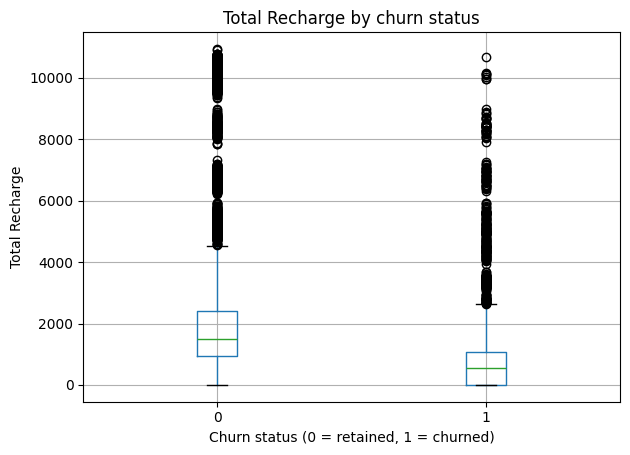

<Figure size 700x400 with 0 Axes>

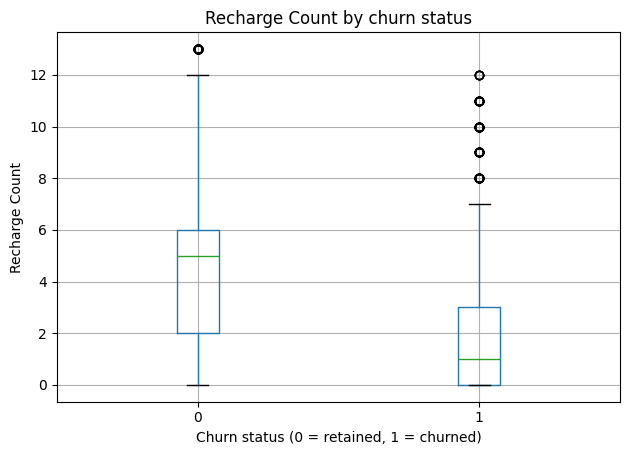

<Figure size 700x400 with 0 Axes>

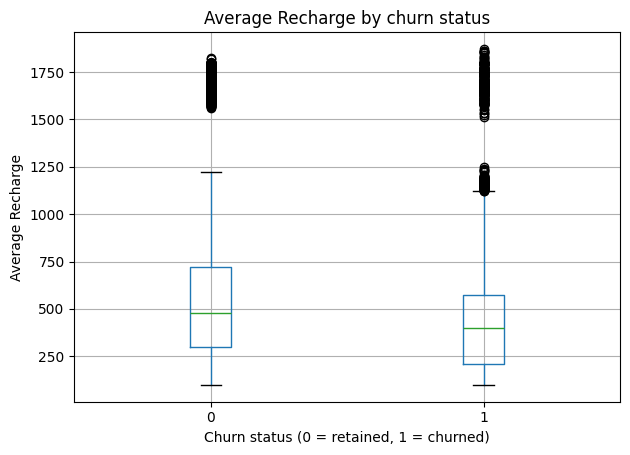

In [66]:
# Distribution checks / visualisations for Task 1
for metric in ["total_recharge","recharge_count","average_recharge"]:
    plot_df = validation_df if metric != "average_recharge" else active_df
    plt.figure(figsize=(7,4))
    plot_df.boxplot(column=metric, by="is_churned")
    plt.title(f"{metric.replace('_',' ').title()} by churn status")
    plt.suptitle("")
    plt.xlabel("Churn status (0 = retained, 1 = churned)")
    plt.ylabel(metric.replace("_"," ").title())
    plt.tight_layout()
    plt.show()

## Task 2 — Recharge-frequency categories and churn rate
Categories: Low = 0–2 recharges, Medium = 3–5, High = 6 or more.

For the low vs high comparison, H₀: churn proportions are equal. H₁: churn proportions differ. This is a two-tailed two-proportion Z-test.

In [67]:
validation_df["frequency_category"] = pd.cut(
    validation_df.recharge_count, bins=[-1,2,5,np.inf],
    labels=["Low frequency","Medium frequency","High frequency"]
)
frequency_summary = validation_df.groupby("frequency_category",observed=False).agg(
    subscribers=("customer_id","count"), churned_subscribers=("is_churned","sum")
).reset_index()
frequency_summary["churn_rate_pct"] = 100*frequency_summary.churned_subscribers/frequency_summary.subscribers
display(frequency_summary)

low = validation_df[validation_df.frequency_category=="Low frequency"]
high = validation_df[validation_df.frequency_category=="High frequency"]
counts = np.array([low.is_churned.sum(),high.is_churned.sum()])
nobs = np.array([len(low),len(high)])
z_stat,p_z = proportions_ztest(counts,nobs,alternative="two-sided")
low_rate,high_rate = counts[0]/nobs[0],counts[1]/nobs[1]
frequency_test = pd.DataFrame([{
    "Test ID":"T2","Research Question":"Do low- and high-frequency groups have different churn rates?",
    "Group 1":"Low frequency","Group 2":"High frequency",
    "Sample Size 1":len(low),"Sample Size 2":len(high),
    "Churn Rate 1":low_rate,"Churn Rate 2":high_rate,
    "Difference (percentage points)":100*(low_rate-high_rate),
    "Test Used":"Two-proportion Z-test (two-tailed)","Test Statistic":z_stat,
    "p-value":p_z,"Significance Level":0.05,
    "Decision":"Reject H0" if p_z<0.05 else "Fail to reject H0"
}])
display(frequency_test)

,frequency_category,subscribers,churned_subscribers,churn_rate_pct
0,Low frequency,8812,3413,38.731276
1,Medium frequency,5147,1567,30.444919
2,High frequency,8041,246,3.059321


,Test ID,Research Question,Group 1,Group 2,Sample Size 1,Sample Size 2,Churn Rate 1,Churn Rate 2,Difference (percentage points),Test Used,Test Statistic,p-value,Significance Level,Decision
0,T2,Do low- and high-frequency groups have differe...,Low frequency,High frequency,8812,8041,0.387313,0.030593,35.671955,Two-proportion Z-test (two-tailed),56.103292,0.0,0.05,Reject H0


## Task 3 — Tenure and churn status
H₀: mean tenure is equal between churned and retained subscribers. H₁: mean tenure differs. A two-tailed Welch t-test is used.

,Test ID,Research Question,Group 1,Group 2,Sample Size 1,Sample Size 2,Mean 1,Mean 2,Median 1,Median 2,SD 1,SD 2,Difference (Churned - Retained),Test Used,Test Statistic,p-value,Significance Level,Decision
0,T3,Does tenure_days differ by churn status?,Churned,Retained,5226,16774,651.587639,711.879874,633.0,720.0,328.853758,331.753529,-60.292235,Welch independent-samples t-test (two-tailed),-11.548843,1.244091e-30,0.05,Reject H0


<Figure size 700x400 with 0 Axes>

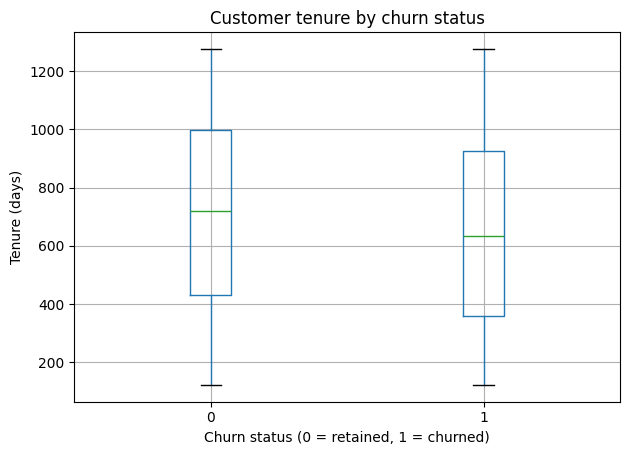

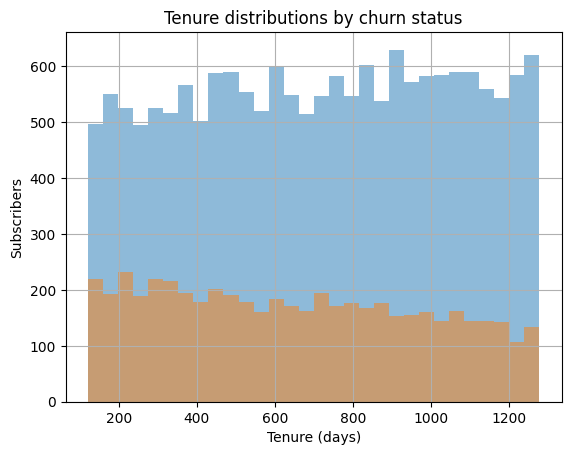

In [68]:
tenure_result = pd.DataFrame([welch_test(validation_df,"tenure_days","T3")])
display(tenure_result)
plt.figure(figsize=(7,4))
validation_df.boxplot(column="tenure_days",by="is_churned")
plt.title("Customer tenure by churn status")
plt.suptitle("")
plt.xlabel("Churn status (0 = retained, 1 = churned)")
plt.ylabel("Tenure (days)")
plt.tight_layout()
plt.show()
validation_df.groupby("is_churned").tenure_days.hist(bins=30,alpha=.5)
plt.title("Tenure distributions by churn status")
plt.xlabel("Tenure (days)")
plt.ylabel("Subscribers")
plt.show()

## Task 4 — Robustness check
Repeat the total-recharge comparison after excluding subscribers with zero recharge transactions.

In [69]:
robustness_result = pd.DataFrame([welch_test(active_df,"total_recharge","T4")])
display(pd.concat([pd.DataFrame([results[0]]),robustness_result],ignore_index=True))
print("Full population:",len(validation_df))
print("Recharge-active population:",len(active_df))

,Test ID,Research Question,Group 1,Group 2,Sample Size 1,Sample Size 2,Mean 1,Mean 2,Median 1,Median 2,SD 1,SD 2,Difference (Churned - Retained),Test Used,Test Statistic,p-value,Significance Level,Decision
0,T1A,Does total_recharge differ by churn status?,Churned,Retained,5226,16774,928.075775,2421.553833,563.0,1495.0,1391.839720,2644.700357,-1493.478058,Welch independent-samples t-test (two-tailed),-53.214114,0.0,0.05,Reject H0
1,T4,Does total_recharge differ by churn status?,Churned,Retained,3582,14707,1354.026801,2761.891888,836.0,1745.0,1499.888085,2652.829016,-1407.865088,Welch independent-samples t-test (two-tailed),-42.322705,0.0,0.05,Reject H0


Full population: 22000
Recharge-active population: 18289


## Consolidated test results

In [70]:
all_results = pd.concat([
    task1_results,
    frequency_test,
    tenure_result,
    robustness_result
],ignore_index=True)
display(all_results)

,Test ID,Research Question,Group 1,Group 2,Sample Size 1,Sample Size 2,Mean 1,Mean 2,Median 1,Median 2,...,SD 2,Difference (Churned - Retained),Test Used,Test Statistic,p-value,Significance Level,Decision,Churn Rate 1,Churn Rate 2,Difference (percentage points)
0,T1A,Does total_recharge differ by churn status?,Churned,Retained,5226,16774,928.075775,2421.553833,563.0,1495.0,...,2644.700357,-1493.478058,Welch independent-samples t-test (two-tailed),-53.214114,0.000000e+00,0.05,Reject H0,NaN,NaN,NaN
1,T1B,Does recharge_count differ by churn status?,Churned,Retained,5226,16774,2.015499,4.361512,1.0,5.0,...,2.792831,-2.346012,Welch independent-samples t-test (two-tailed),-64.180227,0.000000e+00,0.05,Reject H0,NaN,NaN,NaN
2,T1C,Does average_recharge differ by churn status?,Churned,Retained,3582,14707,515.468747,593.621104,399.0,479.0,...,430.900925,-78.152358,Welch independent-samples t-test (two-tailed),-9.821620,1.391981e-22,0.05,Reject H0,NaN,NaN,NaN
3,T2,Do low- and high-frequency groups have differe...,Low frequency,High frequency,8812,8041,NaN,NaN,NaN,NaN,...,NaN,NaN,Two-proportion Z-test (two-tailed),56.103292,0.000000e+00,0.05,Reject H0,0.387313,0.030593,35.671955
4,T3,Does tenure_days differ by churn status?,Churned,Retained,5226,16774,651.587639,711.879874,633.0,720.0,...,331.753529,-60.292235,Welch independent-samples t-test (two-tailed),-11.548843,1.244091e-30,0.05,Reject H0,NaN,NaN,NaN
5,T4,Does total_recharge differ by churn status?,Churned,Retained,3582,14707,1354.026801,2761.891888,836.0,1745.0,...,2652.829016,-1407.865088,Welch independent-samples t-test (two-tailed),-42.322705,0.000000e+00,0.05,Reject H0,NaN,NaN,NaN


## Data export
The notebook exports the subscriber-level data and statistical summary to the reports folder.

In [71]:
from pathlib import Path
out_dir = Path(r"C:\Users\jazee\OneDrive\Desktop\airtel-telecom-analytics\reports")
out_dir.mkdir(exist_ok=True)
validation_df.to_csv(out_dir/"validation_df.csv",index=False)
all_results.to_excel(out_dir/"07_Validation_Summary.xlsx",index=False)
frequency_summary.to_excel(out_dir/"07_Frequency_Summary.xlsx",index=False)
print("Exports saved to",out_dir.resolve())

Exports saved to C:\Users\jazee\OneDrive\Desktop\airtel-telecom-analytics\reports


## Business conclusion — complete from the outputs above
- Summarise statistically significant and non-significant comparisons.
- Interpret differences in rupees, transactions, days, or percentage points.
- Discuss practical importance rather than p-values alone.
- Compare the full population and recharge-active robustness results.
- Note limitations: observational design, possible confounding, skew/extreme values, missing or invalid transactions, and the six-month window.
- Do not claim that recharge frequency causes churn to decrease.